## E202E.1 · Main diagnostic findings

**The 48-state, 432-branch reanalysis is complete. The fixed layer-allocation pilot is running below.**

- **Identical controller results had a mechanical explanation.** The confidence-gated ridge and constant-action models had **no feasible action in all 16 held-out states**. Their 16 Skip decisions were fallbacks, not 16 certified-safe actions.
- **The safety horizon matters.** Skip changed no learner parameters during its intervention and violated no original audit-bank constraint at +32. After the shared conservative continuation, 8/16 Skip outcomes violated the rule at +64. A failure attributed to Skip can therefore come from its common future. The original damage allowances came from 32 minibatches of sparse periodic training, so their training exposure also differs from the 64-minibatch branch assay.
- **The LiDAR oracle has little demonstrated gain beyond a simple fixed choice.** The development-selected fixed action was Skip. Choosing on two augmentation draws and testing the third improved time-averaged LiDAR by **+0.107 [−0.059, +0.277]** across six seed means, and **−0.044 [−0.105, +0.017]** on the two original held-out seeds. These are LiDAR units, not percentage points of accuracy. Only two evaluation seeds limit precision. The independent-draw margin oracle retains a positive margin advantage, so conclusions depend on the target.
- **Action rankings retain some reproducibility.** At +64, pair-order agreement across draws was **72.7% for LiDAR, 80.1% for margin and 82.9% for rank**. Stochasticity alone does not explain every failed decision.
- **Health did not clearly improve the simple history baseline.** Stage/LR-history rank-damage RMSE was 0.01272. Adding health levels/trends gave 0.01357, with essentially unchanged margin-damage RMSE. Adding incoming novelty/redundancy gave 0.01241. Optimizer measurements improved the secondary LiDAR forecast, but health-heavy features did not. All are retrospective two-seed comparisons, with damage-focused alpha selection and paired seed-level intervals in the saved data.

| Action | Original audit-rule rejections at +32 | Rejections at +64 |
| --- | --- | --- |
| Skip | 0 / 16 | 8 / 16 |
| Conservative | 11 / 16 | 12 / 16 |
| Aggressive | 14 / 16 | 15 / 16 |

These rejection counts refer to the operational rank/margin rules, not validated semantic damage. The 90th-percentile empirical model-error bounds are also larger than the allowed peak deterioration: 2.03% versus 0.57% of reference rank, and 4.49% versus 1.78% of reference margin. This helps explain infeasibility, but it is not the sole cause: the constant predictor is infeasible even without an uncertainty bound.

The Pareto sweep separately relaxes incremental rank/margin budgets and compares keeping versus removing absolute/cumulative/recovery rules. The resulting points trade permitted LR intensity against observed audit-bank damage. **No revised threshold was selected or deployed from this exploratory sweep.** Any later revision must be frozen before testing fresh seeds.

The conditional next step is a small **fixed-policy** layer-adaptation study, with trainable heads under encoder-allocation actions and complete Skip as a separate reference. It tests whether a different action space can offer a better compute–representation frontier. This is an exploratory mechanism test, not proof that global LR control cannot work, and it does not fit another controller.


# E202E · What limits global learning-rate control?

**Exploratory reanalysis of 48 states and 432 saved branches. No new counterfactual training.**

All branches use matched images and three paired augmentation draws. Each action lasts 32 minibatches, followed by 32 common conservative minibatches. This identifies finite-bank, short-horizon effects under a shared future; it does not establish semantic learning or full-policy deployment gains.

Independent-draw oracles select an action using two draws and score it on the third, rotating the held-out draw. The same-draw oracle is an optimistic reference. The strongest fixed action is selected on development seeds 1–4. Seeds 5–6 retain the original fit/evaluation split, but this reanalysis is exploratory and they are not fresh confirmation seeds. Intervals resample seed means, not 432 supposedly independent branches. Two-seed intervals have very limited precision.

## Available control value

| Target | Horizon | Dev fixed | Same-draw gain | Independent-draw gain, all seeds [95% interval] | Independent draw, seeds 5–6 |
| --- | --- | --- | --- | --- | --- |
| lidar | 32 | skip | +0.17539 | +0.11463 [-0.00007, +0.23566] | +0.02051 [-0.02234, +0.06335] |
| margin | 32 | skip | +0.00037 | +0.00028 [+0.00015, +0.00042] | +0.00031 [+0.00007, +0.00056] |
| rank | 32 | skip | +0.07752 | +0.00758 [-0.03417, +0.04724] | +0.03650 [+0.00600, +0.06701] |
| neighbors | 32 | skip | +0.00140 | +0.00007 [-0.00039, +0.00052] | +0.00020 [+0.00003, +0.00036] |
| lidar | 64 | skip | +0.23407 | +0.10713 [-0.05857, +0.27654] | -0.04398 [-0.10478, +0.01681] |
| margin | 64 | skip | +0.00053 | +0.00034 [+0.00018, +0.00050] | +0.00031 [+0.00007, +0.00056] |
| rank | 64 | skip | +0.10024 | +0.01665 [-0.05768, +0.08766] | +0.07189 [+0.00000, +0.14379] |
| neighbors | 64 | skip | +0.00199 | +0.00041 [+0.00008, +0.00067] | +0.00073 [+0.00069, +0.00076] |

An oracle improvement over conservative training can largely mean choosing Skip. The additional advantage over a development-selected fixed action is the relevant scheduling opportunity. LiDAR remains an unvalidated learning proxy here. Raw rank and neighborhood scores are diagnostics, not semantic objectives. Cross-bank oracle results are saved separately in the JSON.

### Independent-draw protective oracle

| Scope | Mean LR intensity (aggressive = 1) | Actual rejection on third draw | No feasible training-draw action | Action counts |
| --- | --- | --- | --- | --- |
| all_six_seeds | 0.123 | 62.5% | 53.5% | {'conservative': 20, 'skip': 113, 'aggressive': 11} |
| original_heldout_seeds | 0.146 | 58.3% | 52.1% | {'conservative': 6, 'aggressive': 5, 'skip': 37} |

This oracle selects the highest permitted LR using two draws under the original safety rule, then evaluates safety on the independent third draw. Its training intensity is not semantic utility. Rejection can include pre-existing damage and the shared conservative continuation. A fallback is not certified safe.

## Decisions and feasible actions

| Predictor / selector | Constraint ablation | Skip | Conservative | Aggressive | Empty feasible set | Actual unsafe rate |
| --- | --- | --- | --- | --- | --- | --- |
| constant_mean | full | 16 | 0 | 0 | 16 | 50.0% |
| constant_mean | no_absolute_or_cumulative | 16 | 0 | 0 | 16 | 50.0% |
| constant_mean | no_peak | 7 | 0 | 9 | 7 | 87.5% |
| constant_mean | no_recovery | 16 | 0 | 0 | 16 | 50.0% |
| ridge_confident | full | 16 | 0 | 0 | 16 | 50.0% |
| ridge_confident | no_absolute_or_cumulative | 16 | 0 | 0 | 16 | 50.0% |
| ridge_confident | no_peak | 7 | 1 | 8 | 7 | 87.5% |
| ridge_confident | no_recovery | 16 | 0 | 0 | 16 | 50.0% |
| ridge_learning_confident | full | 16 | 0 | 0 | 16 | 50.0% |
| ridge_learning_confident | no_absolute_or_cumulative | 16 | 0 | 0 | 16 | 50.0% |
| ridge_learning_confident | no_peak | 14 | 0 | 2 | 7 | 56.2% |
| ridge_learning_confident | no_recovery | 16 | 0 | 0 | 16 | 50.0% |
| ridge_learning_mean | full | 15 | 0 | 1 | 11 | 50.0% |
| ridge_learning_mean | no_absolute_or_cumulative | 15 | 0 | 1 | 11 | 50.0% |
| ridge_learning_mean | no_peak | 13 | 0 | 3 | 5 | 56.2% |
| ridge_learning_mean | no_recovery | 16 | 0 | 0 | 13 | 50.0% |
| ridge_mean | full | 15 | 0 | 1 | 11 | 50.0% |
| ridge_mean | no_absolute_or_cumulative | 15 | 0 | 1 | 11 | 50.0% |
| ridge_mean | no_peak | 6 | 1 | 9 | 5 | 87.5% |
| ridge_mean | no_recovery | 16 | 0 | 0 | 13 | 50.0% |
| two_draw_oracle | full | 12 | 2 | 2 | 8 | 56.2% |
| two_draw_oracle | no_absolute_or_cumulative | 12 | 2 | 2 | 8 | 56.2% |
| two_draw_oracle | no_peak | 6 | 1 | 9 | 5 | 87.5% |
| two_draw_oracle | no_recovery | 13 | 2 | 1 | 10 | 56.2% |

A default Skip when no action is feasible is explicitly counted as a fallback, not a certified-safe action. An actual Skip branch still contains the 32-minibatch conservative continuation. Already-outside states use the original recovery rule rather than the ordinary peak/floor constraints.

## Constraint-specific rejection

| Source | Action | Active constraint | Active states | Rejected |
| --- | --- | --- | --- | --- |
| constant_mean | aggressive | margin_cumulative | 9 | 0.0% |
| constant_mean | aggressive | margin_floor | 9 | 0.0% |
| constant_mean | aggressive | margin_peak | 9 | 100.0% |
| constant_mean | aggressive | rank_cumulative | 9 | 0.0% |
| constant_mean | aggressive | rank_floor | 9 | 0.0% |
| constant_mean | aggressive | rank_peak | 9 | 100.0% |
| constant_mean | aggressive | recovery_margin | 7 | 100.0% |
| constant_mean | aggressive | recovery_rank | 7 | 100.0% |
| constant_mean | conservative | margin_cumulative | 9 | 0.0% |
| constant_mean | conservative | margin_floor | 9 | 0.0% |
| constant_mean | conservative | margin_peak | 9 | 100.0% |
| constant_mean | conservative | rank_cumulative | 9 | 0.0% |
| constant_mean | conservative | rank_floor | 9 | 0.0% |
| constant_mean | conservative | rank_peak | 9 | 100.0% |
| constant_mean | conservative | recovery_margin | 7 | 100.0% |
| constant_mean | conservative | recovery_rank | 7 | 100.0% |
| constant_mean | skip | margin_cumulative | 9 | 0.0% |
| constant_mean | skip | margin_floor | 9 | 0.0% |
| constant_mean | skip | margin_peak | 9 | 0.0% |
| constant_mean | skip | rank_cumulative | 9 | 0.0% |
| constant_mean | skip | rank_floor | 9 | 0.0% |
| constant_mean | skip | rank_peak | 9 | 100.0% |
| constant_mean | skip | recovery_margin | 7 | 100.0% |
| constant_mean | skip | recovery_rank | 7 | 100.0% |
| ridge_confident | aggressive | margin_cumulative | 9 | 0.0% |
| ridge_confident | aggressive | margin_floor | 9 | 0.0% |
| ridge_confident | aggressive | margin_peak | 9 | 100.0% |
| ridge_confident | aggressive | rank_cumulative | 9 | 11.1% |
| ridge_confident | aggressive | rank_floor | 9 | 11.1% |
| ridge_confident | aggressive | rank_peak | 9 | 100.0% |
| ridge_confident | aggressive | recovery_margin | 7 | 100.0% |
| ridge_confident | aggressive | recovery_rank | 7 | 100.0% |
| ridge_confident | conservative | margin_cumulative | 9 | 0.0% |
| ridge_confident | conservative | margin_floor | 9 | 0.0% |
| ridge_confident | conservative | margin_peak | 9 | 100.0% |
| ridge_confident | conservative | rank_cumulative | 9 | 0.0% |
| ridge_confident | conservative | rank_floor | 9 | 0.0% |
| ridge_confident | conservative | rank_peak | 9 | 100.0% |
| ridge_confident | conservative | recovery_margin | 7 | 100.0% |
| ridge_confident | conservative | recovery_rank | 7 | 100.0% |
| ridge_confident | skip | margin_cumulative | 9 | 0.0% |
| ridge_confident | skip | margin_floor | 9 | 0.0% |
| ridge_confident | skip | margin_peak | 9 | 100.0% |
| ridge_confident | skip | rank_cumulative | 9 | 0.0% |
| ridge_confident | skip | rank_floor | 9 | 0.0% |
| ridge_confident | skip | rank_peak | 9 | 100.0% |
| ridge_confident | skip | recovery_margin | 7 | 100.0% |
| ridge_confident | skip | recovery_rank | 7 | 100.0% |
| ridge_mean | aggressive | margin_cumulative | 9 | 0.0% |
| ridge_mean | aggressive | margin_floor | 9 | 0.0% |
| ridge_mean | aggressive | margin_peak | 9 | 55.6% |
| ridge_mean | aggressive | rank_cumulative | 9 | 11.1% |
| ridge_mean | aggressive | rank_floor | 9 | 11.1% |
| ridge_mean | aggressive | rank_peak | 9 | 100.0% |
| ridge_mean | aggressive | recovery_margin | 7 | 57.1% |
| ridge_mean | aggressive | recovery_rank | 7 | 85.7% |
| ridge_mean | conservative | margin_cumulative | 9 | 0.0% |
| ridge_mean | conservative | margin_floor | 9 | 0.0% |
| ridge_mean | conservative | margin_peak | 9 | 33.3% |
| ridge_mean | conservative | rank_cumulative | 9 | 0.0% |
| ridge_mean | conservative | rank_floor | 9 | 0.0% |
| ridge_mean | conservative | rank_peak | 9 | 100.0% |
| ridge_mean | conservative | recovery_margin | 7 | 57.1% |
| ridge_mean | conservative | recovery_rank | 7 | 85.7% |
| ridge_mean | skip | margin_cumulative | 9 | 0.0% |
| ridge_mean | skip | margin_floor | 9 | 0.0% |
| ridge_mean | skip | margin_peak | 9 | 11.1% |
| ridge_mean | skip | rank_cumulative | 9 | 0.0% |
| ridge_mean | skip | rank_floor | 9 | 0.0% |
| ridge_mean | skip | rank_peak | 9 | 66.7% |
| ridge_mean | skip | recovery_margin | 7 | 57.1% |
| ridge_mean | skip | recovery_rank | 7 | 71.4% |
| two_draw_oracle | aggressive | margin_cumulative | 9 | 0.0% |
| two_draw_oracle | aggressive | margin_floor | 9 | 0.0% |
| two_draw_oracle | aggressive | margin_peak | 9 | 44.4% |
| two_draw_oracle | aggressive | rank_cumulative | 9 | 11.1% |
| two_draw_oracle | aggressive | rank_floor | 9 | 11.1% |
| two_draw_oracle | aggressive | rank_peak | 9 | 88.9% |
| two_draw_oracle | aggressive | recovery_margin | 7 | 85.7% |
| two_draw_oracle | aggressive | recovery_rank | 7 | 85.7% |
| two_draw_oracle | conservative | margin_cumulative | 9 | 0.0% |
| two_draw_oracle | conservative | margin_floor | 9 | 0.0% |
| two_draw_oracle | conservative | margin_peak | 9 | 44.4% |
| two_draw_oracle | conservative | rank_cumulative | 9 | 0.0% |
| two_draw_oracle | conservative | rank_floor | 9 | 0.0% |
| two_draw_oracle | conservative | rank_peak | 9 | 66.7% |
| two_draw_oracle | conservative | recovery_margin | 7 | 85.7% |
| two_draw_oracle | conservative | recovery_rank | 7 | 85.7% |
| two_draw_oracle | skip | margin_cumulative | 9 | 0.0% |
| two_draw_oracle | skip | margin_floor | 9 | 0.0% |
| two_draw_oracle | skip | margin_peak | 9 | 22.2% |
| two_draw_oracle | skip | rank_cumulative | 9 | 0.0% |
| two_draw_oracle | skip | rank_floor | 9 | 0.0% |
| two_draw_oracle | skip | rank_peak | 9 | 33.3% |
| two_draw_oracle | skip | recovery_margin | 7 | 71.4% |
| two_draw_oracle | skip | recovery_rank | 7 | 71.4% |

The absolute floors and cumulative budgets can be redundant. Grouped constraint ablations remove both together. The original margin cumulative allowance is zero, so it requires terminal margin at least as large as the reference margin. The original peak-loss allowance comes from 32-minibatch periodic-conservative windows, whereas branch outcomes include a 32-minibatch intervention and 32-minibatch dense conservative continuation. The saved actual_32 versus actual_64 rejection tables isolate that horizon mismatch.

## Action-ranking reproducibility

| Target | Minibatches | Pair ordering agreement | Winning action agreement | SD exceeds mean effect magnitude |
| --- | --- | --- | --- | --- |
| lidar | 32 | 75.5% | 66.0% | 39.6% |
| margin | 32 | 75.9% | 68.8% | 41.7% |
| rank | 32 | 81.0% | 73.6% | 33.3% |
| neighbors | 32 | 76.6% | 70.1% | 36.5% |
| lidar | 48 | 74.5% | 66.0% | 40.6% |
| margin | 48 | 77.3% | 69.4% | 33.3% |
| rank | 48 | 81.9% | 77.1% | 31.2% |
| neighbors | 48 | 79.2% | 70.1% | 34.4% |
| lidar | 64 | 72.7% | 62.5% | 38.5% |
| margin | 64 | 80.1% | 72.9% | 35.4% |
| rank | 64 | 82.9% | 75.0% | 28.1% |
| neighbors | 64 | 81.5% | 76.4% | 32.3% |

Pair agreement compares the three action pairs across the three draw pairs within a state. Exact numerical ties are omitted from ordering agreement. Winner ties use deterministic action order. The mask SD uses only three draws, so individual state estimates are imprecise.

## Feature ablation

| Features | Ridge alpha | Rank-damage RMSE | Margin-damage RMSE | LiDAR-difference RMSE | LiDAR pair accuracy | Empty feasible states |
| --- | --- | --- | --- | --- | --- | --- |
| action_only | 10.0 | 0.01424 | 0.03447 | 0.75606 | 79.2% | 16 |
| stage_lr_history | 1.0 | 0.01272 | 0.02965 | 0.82369 | 70.8% | 16 |
| history_plus_incoming | 10.0 | 0.01241 | 0.02925 | 0.78059 | 66.7% | 16 |
| history_plus_health | 100.0 | 0.01357 | 0.02965 | 1.02236 | 72.9% | 16 |
| history_plus_optimizer | 100.0 | 0.01320 | 0.03007 | 0.74723 | 79.2% | 16 |
| history_plus_all | 100.0 | 0.01346 | 0.02962 | 1.01616 | 72.9% | 16 |
| health_without_history | 100.0 | 0.01381 | 0.03105 | 0.96503 | 64.6% | 16 |

The baseline uses observed stage, source policy, cumulative update count and LR exposure. Health adds geometry levels and trends. Incoming features add novelty/redundancy. Optimizer features add measured update size and Adam moments. All models predict action differences and use development-only grouped alpha selection. As in the original model, the shared alpha is selected on the first four damage/end-state targets; LiDAR error is a secondary, untuned readout. Paired seed-level MSE-gain intervals are saved in feature-ablation.json, with only two evaluation seeds. Original-source predictions, RMSE and selected actions are reproduced before these new contrasts are reported. No downstream label is a feature or fitting target.

## Safety–plasticity frontier

The grid varies rank and margin peak-loss allowances independently by 0, 0.5, 1, 2, 4 and 8 times the original development allowances, with and without the prediction-error bound. One family retains absolute/cumulative/recovery rules; a second isolates incremental damage budgets. Both report actual audit-bank damage and permitted training intensity on the third draw. A point is nondominated when no other point has at least as much intensity and no more rank or margin damage, with one strict improvement. The grid uses the original held-out states retrospectively and must not be treated as fresh validation.

**No revised deployment thresholds have been selected or changed.** Any revised thresholds must be frozen in a dated, hashed configuration before an independent fresh-seed test. Seeds 7–9 remain reserved for such confirmation.

## Conditional fixed layer-adaptation frontier

A fixed layer-allocation development pilot will compare complete Skip, trainable heads with a frozen backbone, late-block adaptation, middle-plus-late adaptation, and full adaptation. The trigger is exploratory: the two-draw LiDAR oracle does not establish an advantage over development-selected fixed Skip on held-out seeds, and its six-seed interval includes zero. This is not proof that global LR has no semantic control opportunity. It motivates testing a different mechanism with fixed policies, while the constraint mismatch and unvalidated learning proxy remain separate issues. The pilot uses three development seeds and fresh paired augmentations over the complete original stream. No allocation controller or revised safety thresholds will be deployed.

The proposed allocation actions keep the heads trainable: freeze the whole backbone, train blocks 9–12, train blocks 5–12, or train the complete backbone. Complete Skip freezes the complete learner as a separate baseline. Early group includes the patch/token/position stem and blocks 1–4; the final norm belongs to the late group. A fixed learning rate and layer-wise decay must remain identical on enabled parameters. Establish this fixed-policy compute–representation frontier before fitting any allocation controller.


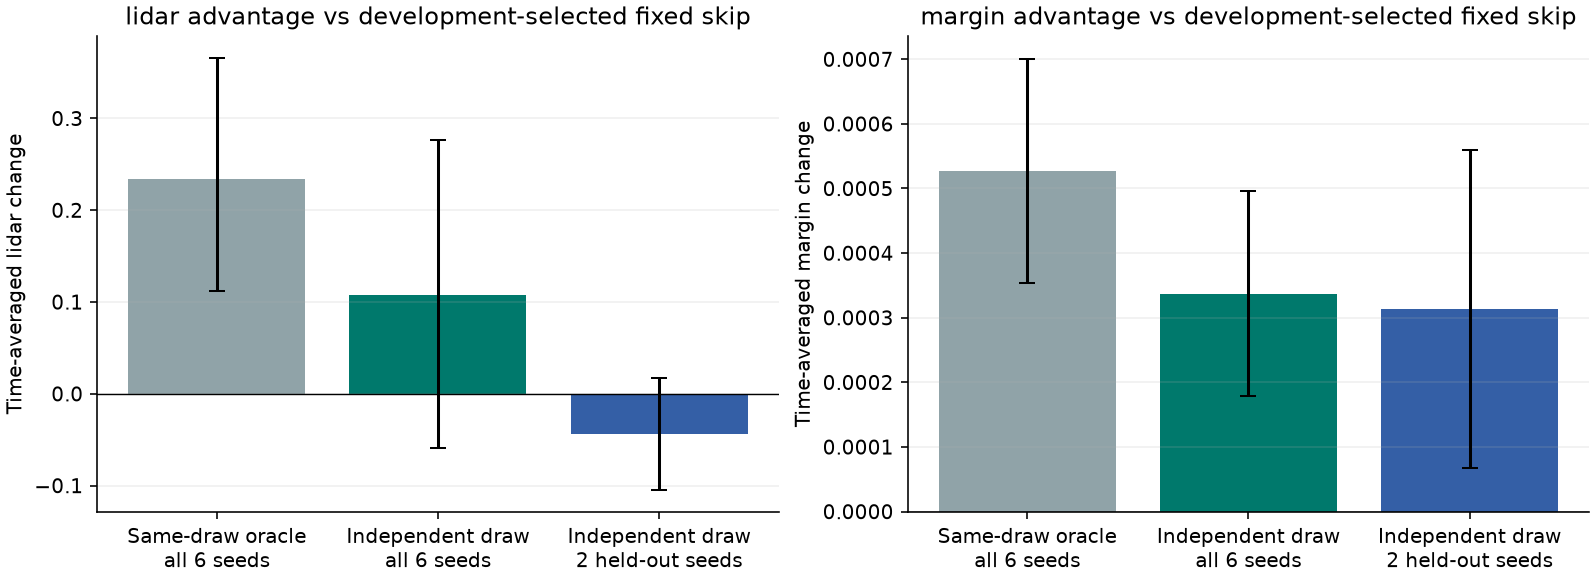

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-simsiam-control\\phase-e\\oracle-advantage.png'))

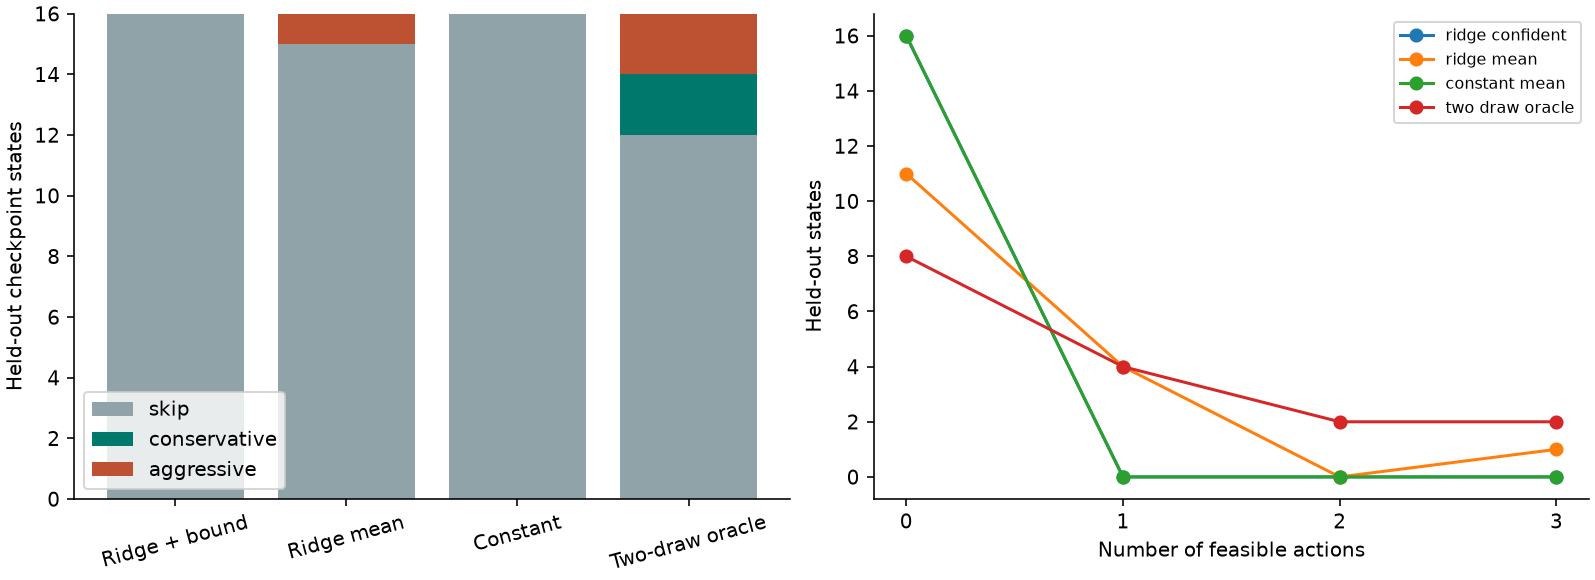

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-simsiam-control\\phase-e\\decisions-feasibility.png'))

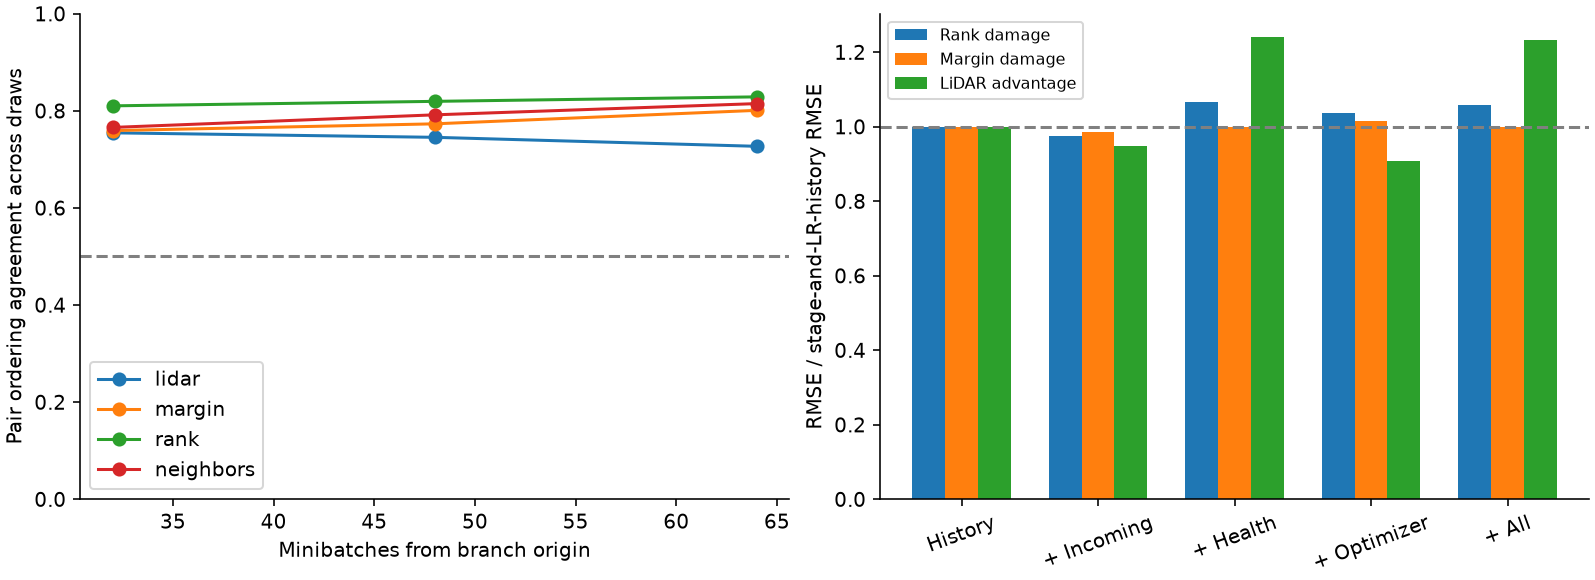

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-simsiam-control\\phase-e\\ranking-ablation.png'))

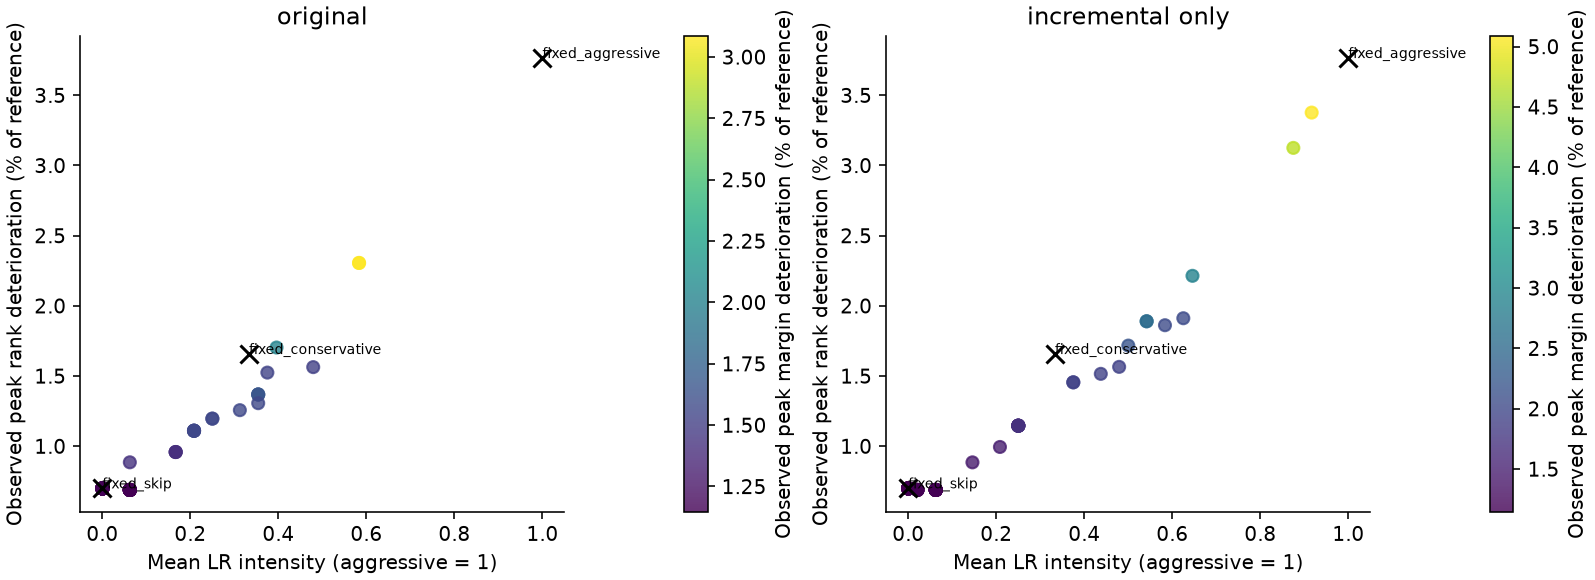

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-simsiam-control\\phase-e\\safety-plasticity.png'))

In [ ]:
import json
from pathlib import Path
summary = json.loads(Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-simsiam-control\\phase-e\\summary.json').read_text(encoding='utf-8'))
summary

## E202E.2 · Fixed layer-adaptation frontier

**Complete** · Fixed layer-allocation frontier saved; no allocation controller fitted · 1/1 minibatches.  
Completed trajectories: 15/15. **ETA: Wed 11:52 Stockholm**, updating from measured throughput.  
Updated 2026-11-18T11:52:59.759718+01:00. 

This is a fixed-policy development pilot, not a new controller or hundreds of counterfactual branches. Three development seeds use fresh paired augmentation streams over the complete original BDD walk (53,903 images, 1,693 minibatches per seed). All policies start from the same pretrained DINO encoder and settled SimSiam heads. The base LR is fixed at 3e-5 with the original 0.75 layer-wise decay and AdamW protections. Enabled parameters retain exactly the same LR scales across actions. Groups are built before freezing parameters.

| Policy | Encoder updates | Head updates |
| --- | --- | --- |
| Complete Skip | None | None |
| Freeze backbone | None | Every minibatch |
| Late adaptation | Blocks 9–12 and final norm | Every minibatch |
| Middle + late | Blocks 5–12 and final norm | Every minibatch |
| Full adaptation | Entire encoder | Every minibatch |

The early group contains the input stem, token/position parameters and blocks 1–4. Frozen parameters are checked by full tensor hashes, and their AdamW state must remain untouched. Training inputs and augmentation RNG are paired by seed and minibatch across policies. A frozen-backbone action can improve the heads while leaving the encoder unchanged; projector changes must not count as encoder learning.

Primary descriptive outcomes are fixed-bank LiDAR, retrieval margin and reference-neighborhood retention against actual runtime. RankMe, centered rank, feature dispersion and layer-wise CKA remain diagnostics. Five frozen downstream tasks (scene, weather, lighting, traffic light and pedestrian) are reported externally with linear and kNN readouts. Labels do not select the LR, allocation or thresholds. No safety threshold is tuned or deployed in this pilot.

Only one rolling full learner/optimizer/AMP checkpoint is retained, at 100-minibatch intervals and readouts. Completed trajectories retain JSON readouts and fingerprints. A restart recomputes at most the work since the last durable save. Training/data time, health measurement time, labeled external evaluation time and total wall time are reported separately.

### Completed fixed policies

| Seed | Policy | Encoder blocks | Mean LiDAR | Mean margin | Final neighbors | Training + data min | Health min | External min | Total min |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | freeze-backbone | [] | 66.323 | 0.03830 | 1.000 | 4.80 | 0.87 | 0.38 | 6.40 |
| 1 | full | [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | 60.785 | 0.04044 | 0.326 | 13.26 | 0.81 | 0.36 | 15.24 |
| 1 | late | [9, 10, 11, 12] | 65.761 | 0.04972 | 0.402 | 7.48 | 0.83 | 0.36 | 9.19 |
| 1 | middle-late | [5, 6, 7, 8, 9, 10, 11, 12] | 62.398 | 0.04235 | 0.377 | 10.26 | 0.82 | 0.36 | 12.09 |
| 1 | skip | [] | 66.323 | 0.03830 | 1.000 | 0.00 | 0.90 | 0.38 | 1.80 |
| 2 | freeze-backbone | [] | 66.323 | 0.03830 | 1.000 | 4.70 | 0.85 | 0.36 | 6.27 |
| 2 | full | [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | 61.126 | 0.03855 | 0.329 | 13.19 | 0.81 | 0.35 | 15.10 |
| 2 | late | [9, 10, 11, 12] | 65.438 | 0.05078 | 0.391 | 7.45 | 0.83 | 0.36 | 9.12 |
| 2 | middle-late | [5, 6, 7, 8, 9, 10, 11, 12] | 61.476 | 0.04355 | 0.410 | 10.21 | 0.82 | 0.36 | 11.95 |
| 2 | skip | [] | 66.323 | 0.03830 | 1.000 | 0.00 | 0.87 | 0.37 | 1.66 |
| 3 | freeze-backbone | [] | 66.323 | 0.03830 | 1.000 | 5.12 | 0.90 | 0.38 | 6.80 |
| 3 | full | [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | 63.013 | 0.04070 | 0.301 | 14.36 | 0.88 | 0.39 | 16.57 |
| 3 | late | [9, 10, 11, 12] | 64.725 | 0.05041 | 0.440 | 8.08 | 0.93 | 0.39 | 10.06 |
| 3 | middle-late | [5, 6, 7, 8, 9, 10, 11, 12] | 65.129 | 0.04050 | 0.330 | 10.99 | 0.87 | 0.38 | 12.98 |
| 3 | skip | [] | 66.323 | 0.03830 | 1.000 | 0.00 | 0.86 | 0.36 | 1.64 |

### External frozen-encoder readouts

| Seed | Policy | Scene linear | Scene kNN | Weather linear | Lighting linear | Traffic light linear | Pedestrian linear |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | freeze-backbone | 56.25% | 40.52% | 51.10% | 70.14% | 62.86% | 69.04% |
| 1 | full | 61.26% | 48.58% | 50.44% | 71.82% | 67.72% | 68.06% |
| 1 | late | 58.05% | 47.98% | 50.86% | 72.48% | 68.90% | 69.77% |
| 1 | middle-late | 58.37% | 48.66% | 51.85% | 69.11% | 68.30% | 70.41% |
| 1 | skip | 56.25% | 40.52% | 51.10% | 70.14% | 62.86% | 69.04% |
| 2 | freeze-backbone | 56.25% | 40.52% | 51.10% | 70.14% | 62.86% | 69.04% |
| 2 | full | 61.10% | 47.63% | 50.94% | 71.77% | 67.26% | 68.03% |
| 2 | late | 57.32% | 50.57% | 49.78% | 73.78% | 71.17% | 67.88% |
| 2 | middle-late | 61.97% | 48.74% | 53.58% | 72.83% | 71.19% | 67.41% |
| 2 | skip | 56.25% | 40.52% | 51.10% | 70.14% | 62.86% | 69.04% |
| 3 | freeze-backbone | 56.25% | 40.52% | 51.10% | 70.14% | 62.86% | 69.04% |
| 3 | full | 58.89% | 42.49% | 52.31% | 71.60% | 67.57% | 66.49% |
| 3 | late | 56.62% | 49.91% | 47.79% | 72.63% | 69.91% | 69.68% |
| 3 | middle-late | 59.98% | 47.12% | 51.23% | 71.26% | 69.66% | 67.35% |
| 3 | skip | 56.25% | 40.52% | 51.10% | 70.14% | 62.86% | 69.04% |


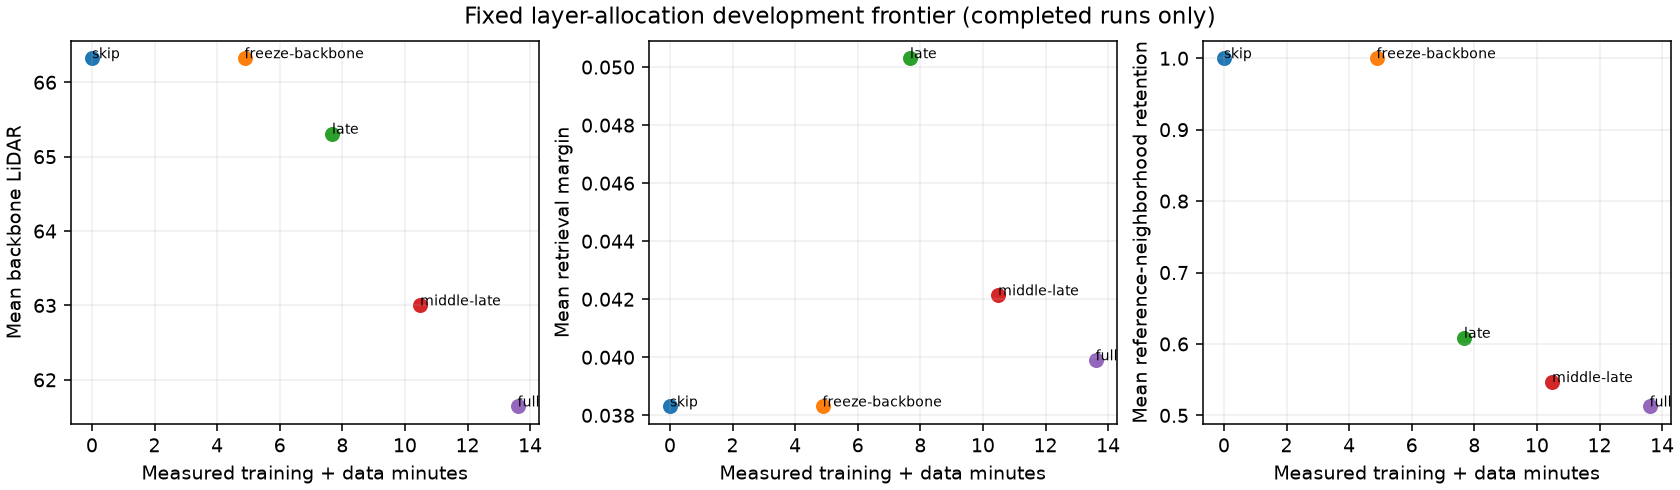

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-simsiam-control\\phase-e\\layer-frontier\\frontier.png'))